# Spatial Interpolation Practice

This notebook demonstrates the concept of spatial interpolation using **Weighted Averages** with a **Station-Specific Decorrelation Scale**.

## Objective
Interpolate missing Dissolved Oxygen (DO) values for specific stations based on the values of their neighbors. 
Instead of a simple average or generic inverse distance weighting (IDW), we use a weighting function based on the **Decorrelation Scale (R)** calculated for the target station.

The core formula for the estimated value $\hat{Z}$ at a target location is:

$$ \hat{Z}_{target} = \frac{\sum_{i=1}^{n} w_i \cdot Z_i}{\sum_{i=1}^{n} w_i} $$

Where $Z_i$ is the value at neighbor $i$, and $w_i$ is the weight.

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Set style for plots
sns.set_style("whitegrid")
plt.rcParams['figure.figsize'] = (10, 6)

## 1. Mathematical Basis: Weighting Functions

We use decay functions to determine the weight $w$ based on the distance $d$ and the decorrelation scale $R$ (Range).

### A. Exponential Decay
$$ w = \exp\left(-\frac{d}{R}\right) $$
The weight drops by factor $1/e$ when distance equals the scale $R$.

### B. Gaussian Decay
$$ w = \exp\left(-\frac{d^2}{2R^2}\right) $$
This has a bell-curve shape, giving higher weights to very close neighbors and dropping off faster after $R$.

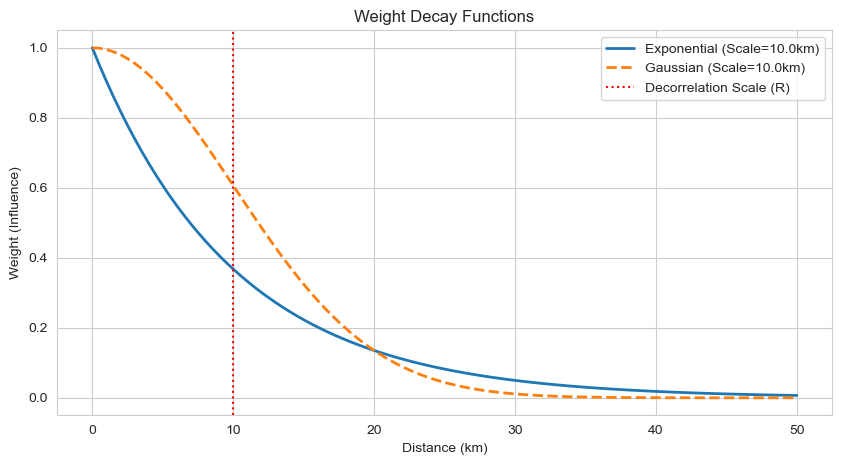

In [3]:
def exponential_weight(distance, scale):
    return np.exp(-distance / scale)

def gaussian_weight(distance, scale):
    return np.exp(-(distance**2) / (2 * scale**2))

# Visualization of the functions
distances = np.linspace(0, 50, 100)
scale_ex = 10.0  # Let's assume a decorrelation scale of 10km

weights_exp = exponential_weight(distances, scale_ex)
weights_gauss = gaussian_weight(distances, scale_ex)

plt.figure(figsize=(10, 5))
plt.plot(distances, weights_exp, label=f'Exponential (Scale={scale_ex}km)', linewidth=2)
plt.plot(distances, weights_gauss, label=f'Gaussian (Scale={scale_ex}km)', linestyle='--', linewidth=2)
plt.axvline(x=scale_ex, color='red', linestyle=':', label='Decorrelation Scale (R)')
plt.title('Weight Decay Functions')
plt.xlabel('Distance (km)')
plt.ylabel('Weight (Influence)')
plt.legend()
plt.show()

## 2. Generate Simple Sample Data

Let's create a synthetic dataset simulating our problem:
- 5 Stations
- Coordinates (x, y)
- Existing DO values (one missing)
- Varying Decorrelation Scales

In [4]:
# Create sample data
data = {
    'Station_ID': ['S1', 'S2', 'S3', 'S4', 'Target_S5'],
    'X_km': [10, 20, 12, 35, 25],      # X coordinate
    'Y_km': [10, 15, 30, 25, 20],      # Y coordinate
    'DO_Value': [7.5, 6.8, 8.2, 5.5, np.nan], # Target_S5 is missing
    'Decorrelation_Scale_km': [15, 12, 20, 10, 15] # Scale for each station
}

df_stations = pd.DataFrame(data).set_index('Station_ID')
print("Sample Data:")
df_stations

Sample Data:


,X_km,Y_km,DO_Value,Decorrelation_Scale_km
Station_ID,,,,
S1,10,10,7.5,15
S2,20,15,6.8,12
S3,12,30,8.2,20
S4,35,25,5.5,10
Target_S5,25,20,NaN,15


## 3. Calculate Distances

For this sample, we use Euclidean distance. In the real analysis, you would use Haversine (Great circle) distance or a pre-calculated distance matrix.

In [5]:
from scipy.spatial.distance import pdist, squareform

# Calculate pairwise Euclidean distances
coords = df_stations[['X_km', 'Y_km']]
dist_array = pdist(coords, metric='euclidean')
dist_matrix = pd.DataFrame(squareform(dist_array), index=df_stations.index, columns=df_stations.index)

print("Distance Matrix (km):")
dist_matrix

Distance Matrix (km):


Station_ID,S1,S2,S3,S4,Target_S5
Station_ID,,,,,
S1,0.000000,11.180340,20.099751,29.154759,18.027756
S2,11.180340,0.000000,17.000000,18.027756,7.071068
S3,20.099751,17.000000,0.000000,23.537205,16.401219
S4,29.154759,18.027756,23.537205,0.000000,11.180340
Target_S5,18.027756,7.071068,16.401219,11.180340,0.000000


## 4. Interpolation Process

We want to fill `Target_S5`. 
1. We look up its `Decorrelation_Scale_km` (which is 15).
2. We find distances to `S1`, `S2`, `S3`, `S4`.
3. We calculate weights using the Exponential function.
4. We compute the weighted mean.

In [6]:
def interpret_station_value(target_id, df_vals, dist_mat, weighting_func='exponential'):
    # 1. Get Target Properties
    target_scale = df_vals.loc[target_id, 'Decorrelation_Scale_km']
    
    # 2. Identify Neighbors (All other stations with valid data)
    # Filter out the target itself and any other NaNs
    neighbors = df_vals[df_vals['DO_Value'].notna()].index
    
    print(f"Target: {target_id}, Scale: {target_scale} km")
    print("Neighbors:", neighbors.tolist())
    
    # 3. Get Distances and Values
    dists = dist_mat.loc[target_id, neighbors]
    values = df_vals.loc[neighbors, 'DO_Value']
    
    # 4. Calculate Weights
    if weighting_func == 'exponential':
        weights = exponential_weight(dists, target_scale)
    elif weighting_func == 'gaussian':
        weights = gaussian_weight(dists, target_scale)
        
    # Display calculation steps
    calc_df = pd.DataFrame({
        'Distance': dists,
        'Value': values,
        'Weight': weights,
        'Weighted_Val': values * weights
    })
    print("\nCalculation Table:")
    print(calc_df)
    
    # 5. Weighted Average
    weighted_avg = (values * weights).sum() / weights.sum()
    
    return weighted_avg, calc_df

# Perform Interpolation
estimated_value, details = interpret_station_value('Target_S5', df_stations, dist_matrix, 'exponential')
print(f"\nEstimated DO Value for Target_S5: {estimated_value:.4f}")

Target: Target_S5, Scale: 15 km
Neighbors: ['S1', 'S2', 'S3', 'S4']

Calculation Table:
             Distance  Value    Weight  Weighted_Val
Station_ID                                          
S1          18.027756    7.5  0.300637      2.254780
S2           7.071068    6.8  0.624125      4.244050
S3          16.401219    8.2  0.335070      2.747577
S4          11.180340    5.5  0.474565      2.610109

Estimated DO Value for Target_S5: 6.8361


## 5. Visualizing the Result

Let's plot the stations physically. The size of the points will correspond to the weight they contributed to the target.

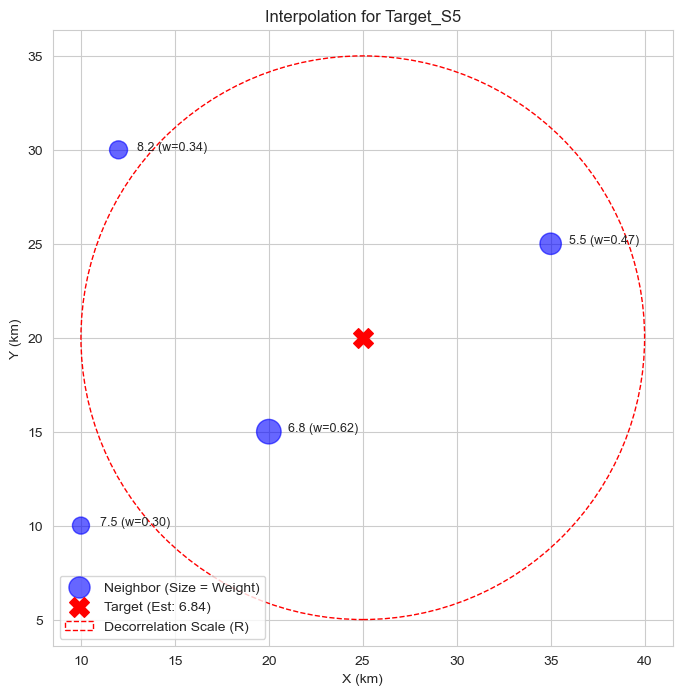

In [7]:
# Plotting
plt.figure(figsize=(8, 8))

# Plot Neighbors
neighbors = details.index
plt.scatter(df_stations.loc[neighbors, 'X_km'], df_stations.loc[neighbors, 'Y_km'], 
            s=details['Weight']*500, c='blue', alpha=0.6, label='Neighbor (Size = Weight)')

# Annotate Neighbors with Values
for idx in neighbors:
    plt.text(df_stations.loc[idx, 'X_km']+1, df_stations.loc[idx, 'Y_km'], 
             f"{df_stations.loc[idx, 'DO_Value']} (w={details.loc[idx, 'Weight']:.2f})", 
             fontsize=9)

# Plot Target
target = 'Target_S5'
plt.scatter(df_stations.loc[target, 'X_km'], df_stations.loc[target, 'Y_km'], 
            s=200, c='red', marker='X', label=f'Target (Est: {estimated_value:.2f})')

# Draw Decorrelation Scale Radius
circle = plt.Circle((df_stations.loc[target, 'X_km'], df_stations.loc[target, 'Y_km']), 
                    df_stations.loc[target, 'Decorrelation_Scale_km'], 
                    color='red', fill=False, linestyle='--', label='Decorrelation Scale (R)')
plt.gca().add_patch(circle)

plt.title(f"Interpolation for {target}")
plt.xlabel("X (km)")
plt.ylabel("Y (km)")
plt.legend(loc='lower left')
plt.axis('equal')
plt.grid(True)
plt.show()